# Examinerande inlämningsuppgift - Hälsostudie
Victor Lundström

## Introduktion
Denna notebook redogör för statistisk analys av hälsodata inför examinerande inlämningsuppgift.
Del 1 går igenom en utforskande analys av datans innehåll, datatyper och fördelning. Del 2 går sedan vidare och ser på mönster och eventuella samband i datan. På grund av att inlämningsuppgiften inte kommer med någon specifik frågeställning annat än att datan skall undersökas statistiskt så har inte analysen genomförts i någon mer detaljerad ordning.

# Del 1
#### Importera samtliga bibliotek som krävs för analysen.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from health_analyzer import HealthAnalyzer

#### Sedan läser vi in datan

Datasetet kommer i form av en CSV-fil och läses in med pandas `read_csv`.
Med hjälp av `df.head()` kan vi även göra en första inspektion av datan. Om inget annat anges så
presenteras bara de första fem raderna med `head()`. Skulle man vilja se ytterligare rader kan man 
redigera uttrycket med valfri siffra, exempelvis `head(20)`, varpå 20 rader visas.

Dokumentation:
- [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
- [DataFrame.head](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)

In [2]:
df = pd.read_csv("health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


Vi kan se att datan innehåller kontinuerliga mått på olika sorters hälsodata som exempelvis längd, vikt, högsta blodtryck (systolsikt blodtryck) och kolesterol. Det finns även binära angivelser (0/1) på huruvida individer röker eller inte, om man besitter någon form av sjukdom samt om man är man eller kvinna.  

### Kontrollera datans struktur

Vi har redan sett vilka kolumnnamn som datan inkluderar med hjälp av `df.head()`, och att det förekommer både kontinuerliga och binära värden. Men, vi skulle även behöva se vilka exakta datatyper som råder i datan, samt om det finns några värden som saknas. För detta kan vi använda `info()`. 

Dokumentation:
- [DataFrame.info](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


Från den här summeringen kan vi se att det finns data från totalt 800 rader (individer) och det finns inga värden som saknas (se kolumnen "Non-Null count"). Majoriteten av datan är i form av numeriska variabler som lagrats antingen som heltal (`int64`), eller som decimaltal (`float64`). Vi kan även se att det finns kategoriska variabler (`str`). Som nämndes i det förra kodblocket så är kolumner "smoker" samt "disease" exemepel på sådana, även om den sistnämnda kolumnen i det här fallet har kodats binärt (0/1) med hjälp av heltal (`int64`). Kolumnen `id` fungerar här som en identifierare och används därför inte som analysvariabel.

### Deskriptiv statistik

Medelvärde, median, minimum och maximum beräknas för age,
weight, height, systolic_bp och cholesterol. Metoden `agg()`
används för att tillämpa flera sammanfattningsfunktioner på
de valda kolumnerna.

Dokumentation:
- [DataFrame.agg](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html)

In [4]:
variables = ["age", "weight", "height", "systolic_bp", "cholesterol"]

analyzer = HealthAnalyzer(df)

summary = analyzer.descriptive_statistics(variables)

summary.round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


#### Medelåldern är 49,43 år och medianåldern 50 år. För samtliga fem variabler ligger medelvärdet nära medianen. Systoliskt blodtryck har ett medelvärde på 149,18 och varierar mellan 106,80 och 185,90.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Fördelning av samtliga kontinuerliga variabler

För att få en bättre överblick över hur variablerna fördelar sig så använder vi metoden `plot_histogram()` i "health_analyzer.py". Denna skapar en samlad figur med fem histogram fördelat över två rader och tre kolumner
med hjälp av matplotlibs `subplots()`. Varje variabel har delats in i 25 intervall med hjälp av seaborns
`histplot()`. Staplarnas höjd visar antalet personer i respektive intervall. Här valdes 25 som intervall arbiträrt, men det bör noteras att ett histograms interval kan påverka hur fördelningen av datan slutligen presenteras.

Dokumentation:
- [seaborn.histplot](https://seaborn.pydata.org/generated/seaborn.histplot.html)
- [Matplotlib: pyplot.subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)

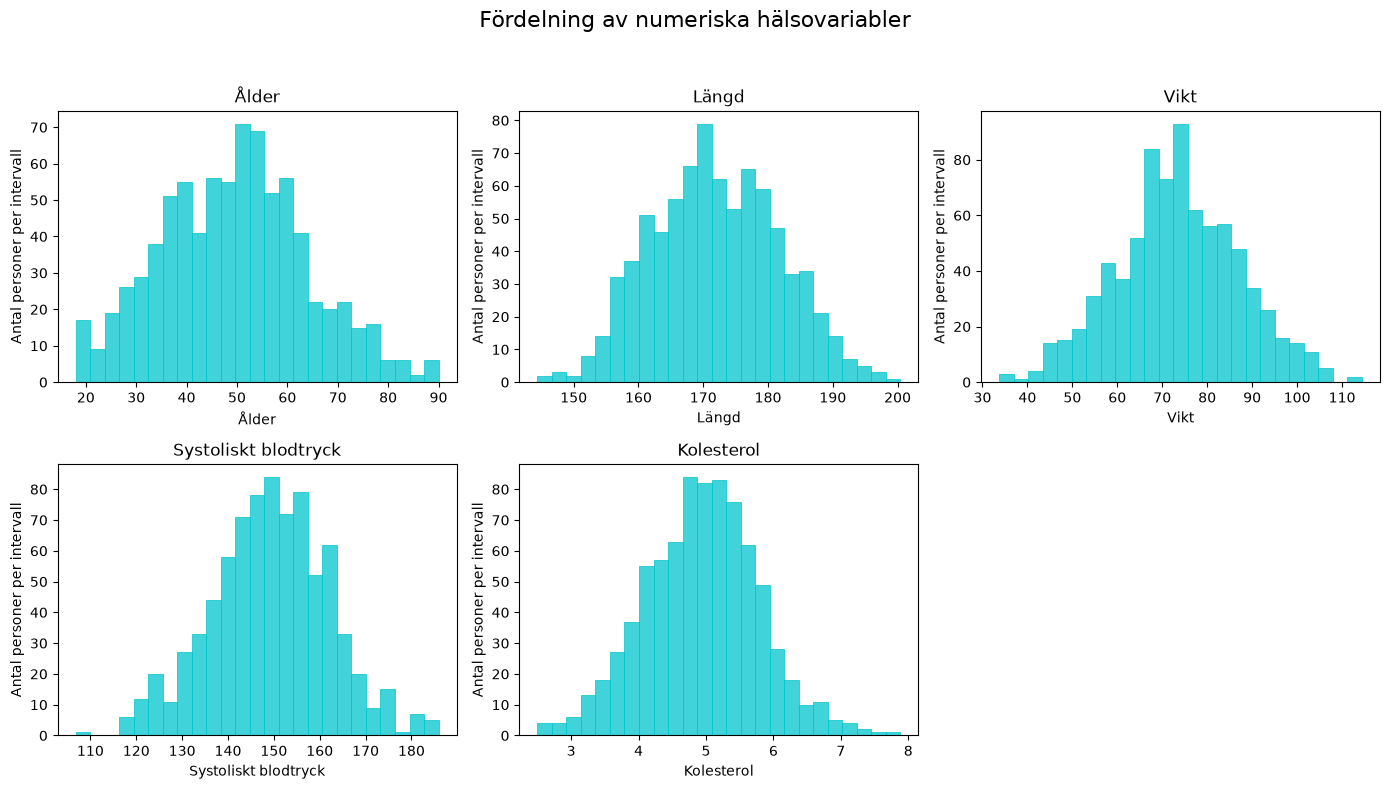

In [5]:
analyzer.plot_histogram()

Från den här presentationen kan vi se att samtliga numeriska variabler, bortsett från "ID" och "disease" som uteslutits, så tycks fördelningen vara mer eller mindre normal. Det vill säga att majoriteten av antalet observationer koncentrerar sig mot datans mitt, samtidigt som antalet observationer på vardera sida om denna mitt symetriskt minskar. Den enda variabel som eventuellt avviker från detta mönster är "Ålder", där vi kan se att observationerna har en "svans" som är förskjuten mot färre observationer av äldre individer fast med något fler yngre individer till vänster. Återigen, en ren visuell inspektion är inte tillräckligt för att avvklara hur pass bra datan förhåller sig till en normalförelning. Exempelvis så skulle Vidare utforskning med hjälp av scipy.stats `continous.fit()` kunna avgöra hur pass bra datan passar en normalfördelning, men det får sparas till en annan analys.

Dokumentation:
- [continous.fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rv_continuous.fit.html#scipy.stats.rv_continuous.fit)

### Viktfördelning per kön

För att undersöka hur variabeln vikt fördelar sig på kön, så har jag valt framställa datan med ett boxplot.
En låda sträcker sig från första till tredje kvartilen och innehåller därför de mittersta 50 procenten av
värdena. Linjen i lådan visar medianen.

De horisontella strecken (morrhåren) högst upp och längst ned på lådorna morrhåren indikerar de yttersta observationerna inom 1,5 gånger kvartilavståndet från lådans kanter. Värden utanför dessa gränser visas som separata punkter. De är potentiella extremvärden, men inte automatiskt felaktiga.

I ett traditionellt boxplot så sammanfattas alla observationer till värden som min, max, medel, IQR och så vidare. För att inte glömma att dessa summeringar utgår individer där variationen fortfarande kan vara stor, så har jag även använt mig av funktionen `sns.swarmplot`. Denna funktion tar varje individuell observation och framställer dessa i form av en punkt, likt ett spridningsdiagram.   

Dokumentation:
- [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)
- [sns.swarmplot](https://seaborn.pydata.org/generated/seaborn.swarmplot.html)

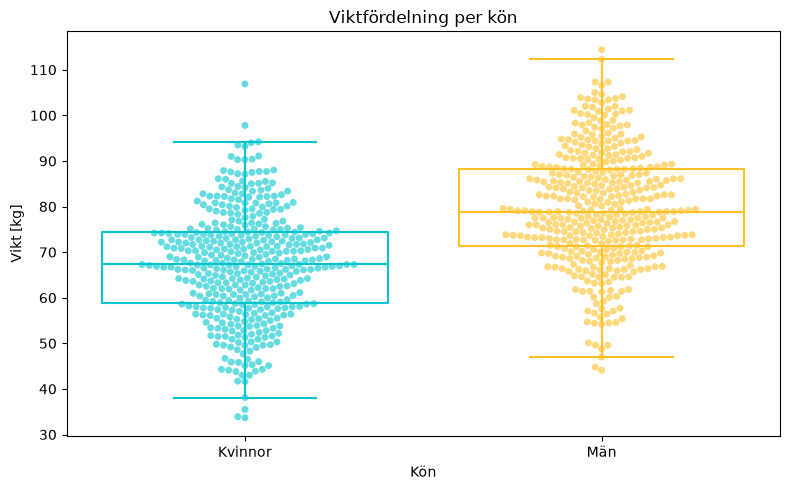

In [6]:
analyzer.plot_boxplot()

Från detta boxplot så kan vi se att viktfördelningen mellan könen överlappar något med varandra, män har en högre medianvikt än kvinnor och båda grupperna har potentiella extremvärden. Spridningen bland de mittersta 50 procenten är även något större för män. Det överlappande spridningsdiagramet skapat av `sns.swarmplot` visar inte att varje enskild observation på något sätt avviker från respektive boxplot.

### Andel rökare och icke-rökare

Ett stapeldiagram används för att jämföra andelen personer i
de två rökkategorierna. Med `value_counts(normalize=True)`
beräknas relativa frekvenser, som multipliceras med 100 för
att uttryckas i procent. `reindex()` bestämmer kategoriernas
ordning och `plot(kind="bar")` skapar stapeldiagrammet.

Y-axeln visas från 0 till 100 procent för att tydliggöra
gruppernas andelar av datasetet.

Dokumentation:
- [Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
- [Series.reindex](https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html)
- [Series.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.bar.html)
- https://stackabuse.com/seaborn-bar-plot-tutorial-and-examples/

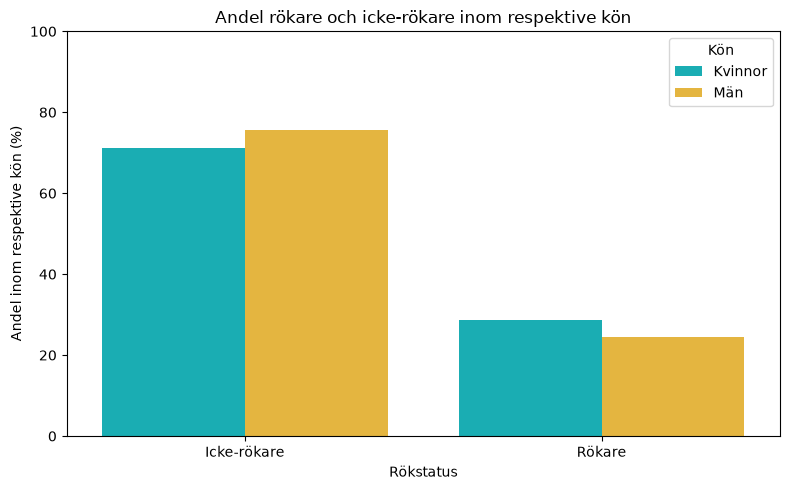

,kön,rökstatus,andel
0,Kvinnor,Icke-rökare,71.2
1,Kvinnor,Rökare,28.8
2,Män,Icke-rökare,75.6
3,Män,Rökare,24.4


In [7]:
smoker_percent = analyzer.plot_smoking_by_sex()

smoker_percent.round(1)

Datan visar att de som inte röker är betydligt fler än de som röker och att inom respektive kategori så är fördelningen relativt jämn mellan könen. 

Så här långt har vi utforskat skillnader och likheter mellan män och kvinnor i variabler som exempelvis ålder, systoliskt blodtryck, vikt, kolesterol och längd. Vi har även sett på likheter och skillnader i andel som röker och inte röker. Vi har dock inte utforskat variabeln "disease" ännu, så nu ska vi gå vidare med den.

Vi börjar med att utforska hur många som har en sjukdom och hur många som inte har en sjukdom.

Antalet observationer som möter kravet "1" eller "0" i `disease` kontrolleras med hjälp av
`value_counts(dropna=False)`. Inställningen "dropna=False" gör att även eventuella
saknade värden visas.

Dokumentation:
- [Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)

In [8]:
df["disease"].value_counts(dropna=False)

disease
0    753
1     47
Name: count, dtype: int64

Av totalt 800 individer så är det 753 st som inte har någon dokumenterad sjukdom och 47 st som har det.

### Simulering av sjukdomsförekomst

Nu ska vi uppskatta hur hög sannolikheten är för förekomst av sjukdom genom att simulera sjukdomsfall hos 1000 slumpmässiga invidider.

Först vi ta fram vad den uppskattade sannolikheten (p) för sjukdom är. Vi kan använda oss utav antalet insjuknade i relation till friska från vårt dataset tillsammans med följande formel:

                                        p = sjuka/totala_individer

Den observerade andelen i det här fallet blir 47/800 = 0.05875, eller 5,875 % 
Vi behöver inte räkna ut detta manuellt, utan vi kan hämta ut genomsnittet genom att summera antalet 1 och 0 i vårt dataset. 

 Med hjälp av `rng.binomial()` genereras ett nytt dataset med en binär angivelse för sjukdom, där "n" representerar individer med rapporterad sjukdom. "p" anger sannolikheten som vi räknar ut i steget "observed_proportion". Sannolikheten fördelas jämnt hos alla 1000 individer. Ett seed på 42 används för reproducerbarhet i samma programmiljö.

Dokumentation:
- [Series.mean](https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html)
- [NumPy Random Generator och seed](https://numpy.org/doc/stable/reference/random/generator.html)
- [Generator.binomial](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.binomial.html)

In [9]:
# Observerad andel med sjukdom: 1 = sjukdom, 0 = ingen sjukdom
observed_proportion = df["disease"].mean()

# Slumpgenerator med fast seed
rng = np.random.default_rng(seed=42)

# Simulera sjukdomsstatus för 1 000 personer
simulated_disease = rng.binomial(
    n=1,
    p=observed_proportion,
    size=1000
)

simulated_proportion = simulated_disease.mean()

# Skillnad uttryckt i procentenheter
difference_pp = (
    simulated_proportion - observed_proportion
) * 100

print(f"Observerad andel: {observed_proportion:.2%}")
print(f"Simulerad andel: {simulated_proportion:.2%}")
print(f"Antal simulerade personer med sjukdom: {simulated_disease.sum()}")
print(f"Skillnad (simulerad − observerad): {difference_pp:.2f} procentenheter")

Observerad andel: 5.88%
Simulerad andel: 5.40%
Antal simulerade personer med sjukdom: 54
Skillnad (simulerad − observerad): -0.47 procentenheter


I datasetet har 47 av 800 personer sjukdomen, vilket motsvarar cirka 5,88 %. Vid simulering av 1000 personer med samma sjukdomssannolikhet fick 54 individer, eller 5,40 %, sjukdomen men skillnaden mellan den observerade och simulerade gruppen utgör knappt en halv procentandel, så ökningen är preliminärt inte så markant.

### Konfidensintervall med normalapproximation av systoliskt blodtryck

Ett 95-procentigt konfidensintervall för populationens medelvärde beräknas som medelvärdet ± 1,96
gånger standardfelet.

Standardfelet skattas som stickprovets standardavvikelse
dividerad med kvadratroten av antalet observationer.
`std(ddof=1)` beräknar stickprovets standardavvikelse.

Normalapproximationen motiveras av det stora stickprovet
(n = 800). Eftersom populationsstandardavvikelsen är okänd
är ett t-intervall ett alternativ, men vid denna
stickprovsstorlek ligger t-kvantilen mycket nära 1,96.

Dokumentation:
- [NIST: Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)
- [Series.std](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html)
- [numpy.sqrt](https://numpy.org/doc/stable/reference/generated/numpy.sqrt.html)
- https://www.youtube.com/watch?v=AuXw6rq4CTs&t=1104s

In [10]:
bp = df["systolic_bp"].dropna() # här skapar vi en ny variabel "bp" med hjälp av kolumnen "systolic_bp"

n = len(bp) # variabeln "n" utgör antalet observationer (800 st)
mean_bp = bp.mean() # här hämtar vi ut medelvärdet i systoliskt blodtryck
std_bp = bp.std(ddof=1) # samt standardavvikelsen
standard_error = std_bp / np.sqrt(n) # här räknar vi ut standardfelet

ci_lower = mean_bp - 1.96 * standard_error
ci_upper = mean_bp + 1.96 * standard_error

print(f"Medelvärde: {mean_bp:.2f}")
print(f"Standardfel: {standard_error:.2f}")
print(f"95 % konfidensintervall: ({ci_lower:.2f}, {ci_upper:.2f})")

Medelvärde: 149.18
Standardfel: 0.45
95 % konfidensintervall: (148.29, 150.07)


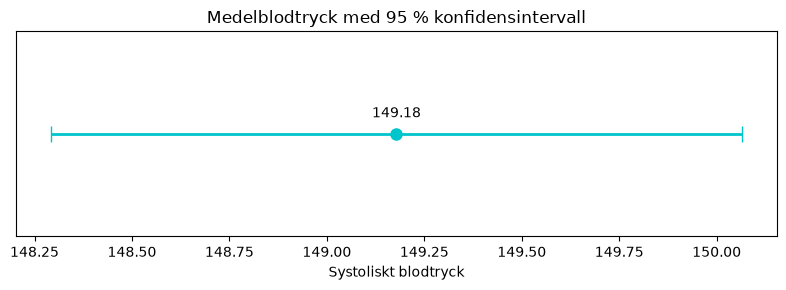

In [11]:
analyzer.plot_confidence_interval(
    mean=mean_bp,
    lower=ci_lower,
    upper=ci_upper
)

Medelvärdet för systoliskt blodtryck är 149,18. Med normalapproximation har ett 95-procentigt konfidensintervall beräknas mellan 148,29 och 150,07. Intervallet är snävt och beskriver osäkerheten i uppskattningen av populationens medelvärde. Vid upprepade slumpmässiga stickprov skulle ungefär 95 % av intervallen som beräknas med denna metod innehålla det sanna populationsmedelvärdet.

### Konfidensintervall med percentil-bootstrap

Här räknar vi ut ett 95-procentigt konfidensintervall med
percentil-bootstrap för jämförelse med normalapproximationen.

Med `choice(replace=True)` dras 10,000 stickprov med återläggning
från de observerade blodtrycksvärdena. Varje stickprov har
samma storlek som originalet, och dess medelvärde beräknas.
Den 2,5:e och 97,5:e percentilen av dessa medelvärden används
som intervallets gränser.

Metoden antar inte att de ursprungliga observationerna är normalfördelade. Den förutsätter dock att observationerna är oberoende. Ett fast seed används för reproducerbarhet.

SciPys dokumentation beskriver percentilmetoden, men i denna
analys implementeras den med NumPy.

Källor:
- [SciPy: percentil-bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)
- [Generator.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)
- [numpy.percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html)

In [12]:
rng_bootstrap = np.random.default_rng(seed=43)

bootstrap_means = np.array([
    rng_bootstrap.choice(bp, size=len(bp), replace=True).mean()
    for _ in range(10000)
])

bootstrap_lower, bootstrap_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print(
    f"95 % bootstrap-intervall: "
    f"({bootstrap_lower:.2f}, {bootstrap_upper:.2f})"
)

95 % bootstrap-intervall: (148.28, 150.06)


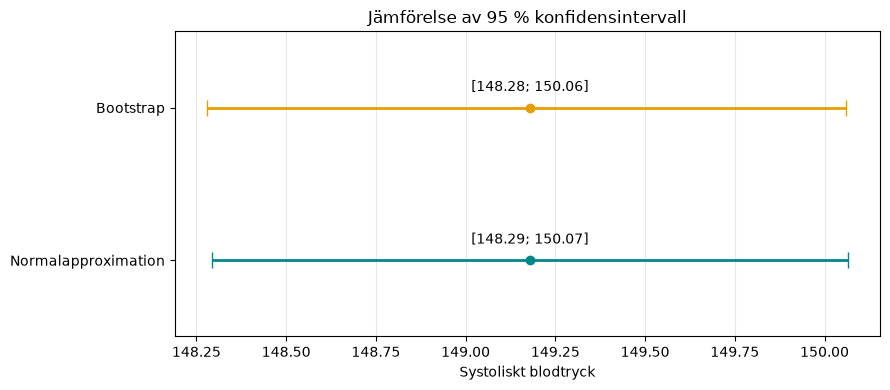

In [13]:
analyzer.plot_ci_comparison(
    mean=mean_bp,
    normal_lower=ci_lower,
    normal_upper=ci_upper,
    bootstrap_lower=bootstrap_lower,
    bootstrap_upper=bootstrap_upper
)

Normalapproximation och percentil-bootstrap ger nästan identiska 95-procentiga konfidensintervall för medelvärdet av systoliskt blodtryck. Slutsatsen påverkas därför mycket lite av metodvalet i detta dataset.

### Jämförelse av systoliskt blodtryck mellan rökare & icke-rökare

Observationerna grupperas efter rökstatus med `groupby()`.
För systoliskt blodtryck beräknas antal observationer,
medelvärde och standardavvikelse inom respektive grupp
med `agg()`.

Sammanfattningen används för att undersöka gruppstorlekar,
skillnaden i medelvärde och spridningen inför hypotesprövningen.
Resultaten visas med två decimaler med `round(2)`.

Dokumentation:
- [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)
- [DataFrameGroupBy.agg](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html)

In [14]:
df.groupby("smoker")["systolic_bp"].agg(
    ["count", "mean", "std"]
).round(2)

,count,mean,std
smoker,,,
No,587,149.05,12.63
Yes,213,149.52,13.27


### Hypotesprövning med ensidigt Welch-t-test

Ett ensidigt Welch-t-test används för att undersöka om
rökare har högre medelvärde för systoliskt blodtryck än
icke-rökare.

- H₀: Rökarnas populationsmedelvärde är lika högt eller lägre.
- H₁: Rökarnas populationsmedelvärde är högre.
- Signifikansnivå: α = 0,05.

Welch-testet väljs eftersom det tillåter olika varians
och olika gruppstorlekar. Testet förutsätter oberoende
observationer. De relativt stora grupperna ger stöd för
approximationen för gruppmedelvärdenas fördelningar.

I `ttest_ind()` väljer `equal_var=False` Welch-testet.
`alternative="greater"` testar om den första gruppens
populationsmedelvärde är högre än den andras. Därför anges
rökarna först. Testets riktning följer uppgiftens hypotes.

Dokumentation:
- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [15]:
from scipy.stats import ttest_ind

smokers_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers_bp = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

test_result = ttest_ind(
    smokers_bp,
    non_smokers_bp,
    equal_var=False,
    alternative="greater"
)

mean_difference = smokers_bp.mean() - non_smokers_bp.mean()

print(f"Skillnad i medelblodtryck: {mean_difference:.2f}")
print(f"t-värde: {test_result.statistic:.3f}")
print(f"p-värde: {test_result.pvalue:.4f}")

Skillnad i medelblodtryck: 0.47
t-värde: 0.450
p-värde: 0.3264


Rökarnas medelblodtryck är 149,52 och icke-rökarnas 149,05,
vilket ger en skillnad på cirka 0,47. Det ensidiga
Welch-t-testet ger t = 0,450 och p = 0,3264.

Eftersom p-värdet är större än signifikansnivån 0,05 kan
nollhypotesen inte förkastas. Analysen ger alltså inte
tillräckligt stöd för att rökare har högre medelblodtryck
än icke-rökare i populationen. Detta innebär inte att
gruppernas medelvärden har visats vara lika.

Jämförelsen tar inte hänsyn till andra variabler, exempelvis
ålder, och visar inte ett orsakssamband.

### Power genom simulering

En power-simulering undersöks genom att simulera oberoende,
normalfördelade blodtrycksvärden hos rökare respektive icke-rökare.
Gruppstorlekar och standardavvikelser hämtas från datasetet.
Icke-rökarnas observerade medelvärde används som baslinje,
medan rökarnas medelvärde förskjuts med en antagen skillnad.

För varje scenario skapas 5,000 dataset. Samma ensidiga
Welch-test genomförs på varje dataset med signifikansnivån
0,05. Andelen signifikanta test uppskattar power när den
antagna skillnaden är positiv. Vid skillnaden noll uppskattas
i stället testets falska positiva frekvens.

Resultaten gäller under simuleringens antaganden. De anger
inte sannolikheten att slutsatsen från det ursprungliga
testet är korrekt. Uppskattningarna innehåller också
Monte Carlo-osäkerhet eftersom antalet simuleringar är begränsat.

Simuleringen implementeras med en egen loop, NumPys
normalgenerator och SciPys Welch-test. Dokumentationen
för `scipy.stats.power` används som metodstöd; den funktionen
anropas inte i vår kod.

Dokumentation:
- [SciPy: simulering av power](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)
- [Generator.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)
- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [16]:
def estimate_power(assumed_difference, seed=44):
    """Uppskatta andelen signifikanta Welch-test i 5 000 simuleringar."""
    rng_power = np.random.default_rng(seed=seed)

    n_simulations = 5000
    alpha = 0.05

    n_smokers = len(smokers_bp)
    n_non_smokers = len(non_smokers_bp)

    baseline_mean = non_smokers_bp.mean()
    sd_smokers = smokers_bp.std(ddof=1)
    sd_non_smokers = non_smokers_bp.std(ddof=1)

    significant_results = 0

    for _ in range(n_simulations):
        simulated_smokers = rng_power.normal(
            loc=baseline_mean + assumed_difference,
            scale=sd_smokers,
            size=n_smokers
        )

        simulated_non_smokers = rng_power.normal(
            loc=baseline_mean,
            scale=sd_non_smokers,
            size=n_non_smokers
        )

        result = ttest_ind(
            simulated_smokers,
            simulated_non_smokers,
            equal_var=False,
            alternative="greater"
        )

        if result.pvalue < alpha:
            significant_results += 1

    estimated_power = significant_results / n_simulations

    return estimated_power

### Jämförelse mellan antagna skillnader

Funktionen `estimate_power()` körs för antagna skillnader på
0, 0,5, 1, 2, 3 och 5. Scenarierna illustrerar hur testets
förmåga förändras med skillnadens storlek. Värdena är valda
för jämförelsen och representerar inte fastställda kliniska
gränser.

Resultaten samlas i en pandas DataFrame. Andelen signifikanta
test redovisas både som andel och procent. Vid skillnaden
noll avser resultatet falska positiva test; för positiva
skillnader avser det power.

Samma seed används för varje scenario, vilket innebär att
samma underliggande slumptal återanvänds. Det underlättar
jämförelsen, men resultaten mellan scenarierna är inte
oberoende.

Dokumentation:
- [SciPy: simulering av power](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)
- [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html)
- [NumPy Random Generator och seed](https://numpy.org/doc/stable/reference/random/generator.html)

In [17]:
power_results = pd.DataFrame({
    "assumed_difference": [0, 0.5, 1, 2, 3, 5]
})

power_results["rejection_rate"] = [
    estimate_power(difference)
    for difference in power_results["assumed_difference"]
]

power_results["rejection_percent"] = (
    power_results["rejection_rate"] * 100
)

power_results.round(2)

,assumed_difference,rejection_rate,rejection_percent
0,0.0,0.05,5.28
1,0.5,0.12,11.76
2,1.0,0.25,24.86
3,2.0,0.60,60.26
4,3.0,0.89,89.36
5,5.0,1.00,99.92


Simuleringen visar att större skillnader är lättare att
upptäcka. En verklig skillnad på 0,5 upptäcktes i cirka
12 procent av simuleringarna, medan en skillnad på 3
upptäcktes i cirka 89 procent.

När gruppernas medelvärden var lika blev 5,28 procent av
testen signifikanta. Det ligger nära den valda
signifikansnivån på 5 procent.

Resultaten gäller under simuleringens antaganden om
normalfördelade, oberoende observationer och de använda
gruppstorlekarna och standardavvikelserna. Den låga powern
för små skillnader visar varför ett icke-signifikant
testresultat inte räcker för att dra slutsatsen att
grupperna är lika.

### Visualisering av power-simuleringen

Andelen signifikanta test ritas mot den antagna verkliga
skillnaden i medelblodtryck. Punkterna visar simuleringsresultaten
för respektive scenario. Linjerna mellan dem är en visuell
sammanbindning och representerar inga ytterligare simuleringar.

Vid skillnaden noll visar grafen den uppskattade falska positiva
frekvensen. Vid positiva skillnader visar den uppskattad power.
En horisontell linje vid 80 procent används som visuell
referensnivå, inte som ett krav i uppgiften.

Dokumentation:
- [matplotlib.pyplot.plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)
- [matplotlib.pyplot.axhline](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)

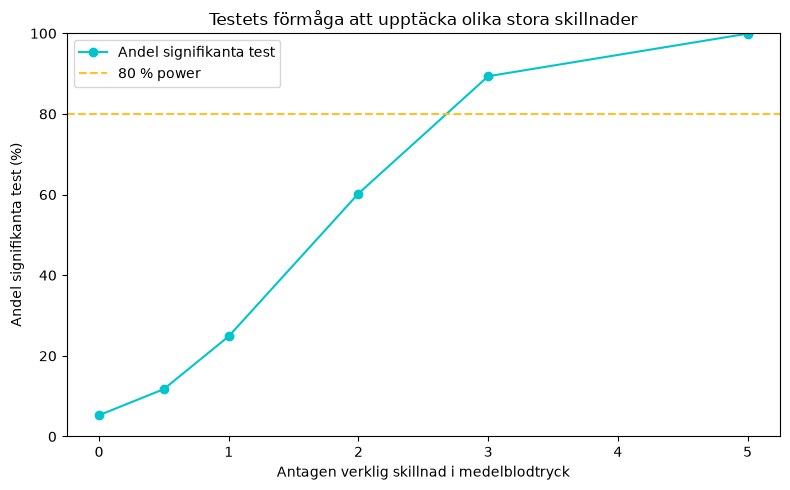

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    power_results["assumed_difference"],
    power_results["rejection_percent"],
    marker="o",
    color="#00C5CD",
    label="Andel signifikanta test"
)

plt.axhline(
    80,
    color="#FFC125",
    linestyle="--",
    label="80 % power"
)

plt.title("Testets förmåga att upptäcka olika stora skillnader")
plt.xlabel("Antagen verklig skillnad i medelblodtryck")
plt.ylabel("Andel signifikanta test (%)")
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()